# Census income classification with scikit-learn

This example uses the standard <a href="https://archive.ics.uci.edu/ml/datasets/Adult">adult census income dataset</a> from the UCI machine learning data repository. We train a k-nearest neighbors classifier using sci-kit learn and then explain the predictions.

In [2]:
import sklearn

import shap

In [3]:
!pip install eli5 pdp

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 108.4/108.4 kB 7.2 MB/s eta 0:00:00
  Created wheel for pdp: filename=pdp-0.3.0-py3-none-any.whl size=6694 sha256=25df898678c051a95b3a497344e72031e1d558721e24e86f796feab2e7e19125
  Stored in directory: /root/.cache/pip/wheels/d8/98/99/2326dc9b39314ceeaa0ce141c50ac7d23671ed03e65c1ea404
Successfully built pdp


In [4]:
!pip install lime

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 15.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283913 sha256=0fa2971bd5b9f1930bbfcbbf4df6ac1c6cc6940674f053fc6377f79a4f4afaef
  Stored in directory: /root/.cache/pip/wheels/7c/04/5c/157dc9106512a6c7a30653ec064490c94a49e0fc8f63d19ab9
Successfully built lime


## Load the census data

In [6]:
X, y = shap.datasets.adult()
X_display, y_display = shap.datasets.adult(display=True)
X_train, X_valid, y_train, y_valid = sklearn.model_selection.train_test_split(X[:1000], y[:1000], test_size=0.2, random_state=7)

In [7]:
X_display, y_display = shap.datasets.adult(display=True)
X_display


,Age,Workclass,Education-Num,Marital Status,Occupation,Relationship,Race,Sex,Capital Gain,Capital Loss,Hours per week,Country
0,39.0,State-gov,13.0,Never-married,Adm-clerical,Not-in-family,White,Male,2174.0,0.0,40.0,United-States
1,50.0,Self-emp-not-inc,13.0,Married-civ-spouse,Exec-managerial,Husband,White,Male,0.0,0.0,13.0,United-States
2,38.0,Private,9.0,Divorced,Handlers-cleaners,Not-in-family,White,Male,0.0,0.0,40.0,United-States
3,53.0,Private,7.0,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0.0,0.0,40.0,United-States
4,28.0,Private,13.0,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0.0,0.0,40.0,Cuba
...,...,...,...,...,...,...,...,...,...,...,...,...
32556,27.0,Private,12.0,Married-civ-spouse,Tech-support,Wife,White,Female,0.0,0.0,38.0,United-States
32557,40.0,Private,9.0,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0.0,0.0,40.0,United-States
32558,58.0,Private,9.0,Widowed,Adm-clerical,Unmarried,White,Female,0.0,0.0,40.0,United-States
32559,22.0,Private,9.0,Never-married,Adm-clerical,Own-child,White,Male,0.0,0.0,20.0,United-States


##About mapping between indexes and categories in adult dataset from SHAP

Based on shap github repository (https://github.com/shap/shap/blob/master/shap/datasets.py) they did the following encoding for the category types:

    data = raw_data.drop(["Education"], axis=1)  # redundant with Education-Num
    filt_dtypes = list(filter(lambda x: x[0] not in ["Target", "Education"], dtypes))
    data["Target"] = data["Target"] == " >50K"
    rcode = {"Not-in-family": 0, "Unmarried": 1, "Other-relative": 2, "Own-child": 3, "Husband": 4, "Wife": 5}
    for k, dtype in filt_dtypes:
        if dtype == "category":
            if k == "Relationship":
                data[k] = np.array([rcode[v.strip()] for v in data[k]])
            else:
                data[k] = data[k].cat.codes

    if display:
        return raw_data.drop(["Education", "Target", "fnlwgt"], axis=1), data["Target"].values
    return data.drop(["Target", "fnlwgt"], axis=1), data["Target"].values

You can follow this procedure in order to keep information about category names (pd.Series.cat.codes <--> pd.Series.cat.categories) and then map them on the plots for its interpretation.

In [8]:
X

,Age,Workclass,Education-Num,Marital Status,Occupation,Relationship,Race,Sex,Capital Gain,Capital Loss,Hours per week,Country
0,39.0,7,13.0,4,1,0,4,1,2174.0,0.0,40.0,39
1,50.0,6,13.0,2,4,4,4,1,0.0,0.0,13.0,39
2,38.0,4,9.0,0,6,0,4,1,0.0,0.0,40.0,39
3,53.0,4,7.0,2,6,4,2,1,0.0,0.0,40.0,39
4,28.0,4,13.0,2,10,5,2,0,0.0,0.0,40.0,5
...,...,...,...,...,...,...,...,...,...,...,...,...
32556,27.0,4,12.0,2,13,5,4,0,0.0,0.0,38.0,39
32557,40.0,4,9.0,2,7,4,4,1,0.0,0.0,40.0,39
32558,58.0,4,9.0,6,1,1,4,0,0.0,0.0,40.0,39
32559,22.0,4,9.0,4,1,3,4,1,0.0,0.0,20.0,39


## Train a k-nearest neighbors classifier


In [9]:
knn = sklearn.neighbors.KNeighborsClassifier()
knn.fit(X_train, y_train)

KNeighborsClassifier()

In [30]:
!pip install lime

In [10]:
import sklearn
import eli5
from eli5.sklearn import PermutationImportance
import lime
import lime.lime_tabular

perm = PermutationImportance(knn)
perm.fit(X_train, y_train)
eli5.show_weights(perm, feature_names=X.columns.values)

Weight,Feature
0.0540 ± 0.0058,Capital Gain
0.0442 ± 0.0142,Hours per week
0.0417 ± 0.0144,Age
0.0275 ± 0.0095,Capital Loss
0.0200 ± 0.0119,Occupation
0.0155 ± 0.0037,Education-Num
0.0077 ± 0.0070,Relationship
0.0052 ± 0.0051,Country
0.0030 ± 0.0025,Race
0.0005 ± 0.0020,Sex


In [11]:
perm.fit(X_valid, y_valid)
eli5.show_weights(perm, feature_names=X.columns.values)

Weight,Feature
0.0470 ± 0.0301,Education-Num
0.0410 ± 0.0133,Capital Loss
0.0410 ± 0.0299,Relationship
0.0340 ± 0.0299,Age
0.0310 ± 0.0194,Capital Gain
0.0250 ± 0.0190,Hours per week
0.0180 ± 0.0422,Occupation
0.0120 ± 0.0215,Marital Status
0.0060 ± 0.0117,Race
0.0040 ± 0.0172,Workclass


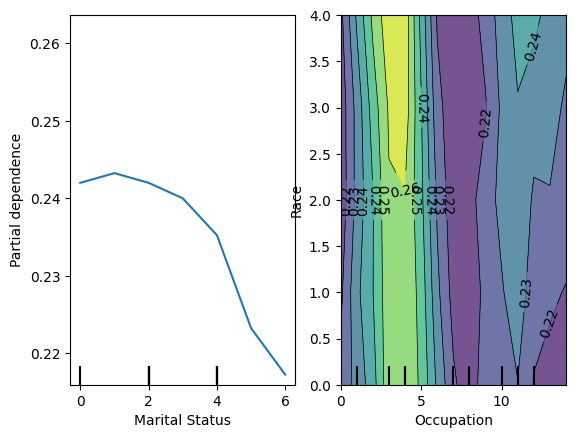

In [33]:
from sklearn.inspection import PartialDependenceDisplay

PartialDependenceDisplay.from_estimator(knn, X_train, [3, (4, 6)], target=0)

In [34]:
!pip install pdpbox

obtain pred_func from the provided model.


  0%|          | 0/6 [00:00<?, ?it/s]

obtain pred_func from the provided model.


  0%|          | 0/9 [00:00<?, ?it/s]

obtain pred_func from the provided model.


  0%|          | 0/54 [00:00<?, ?it/s]

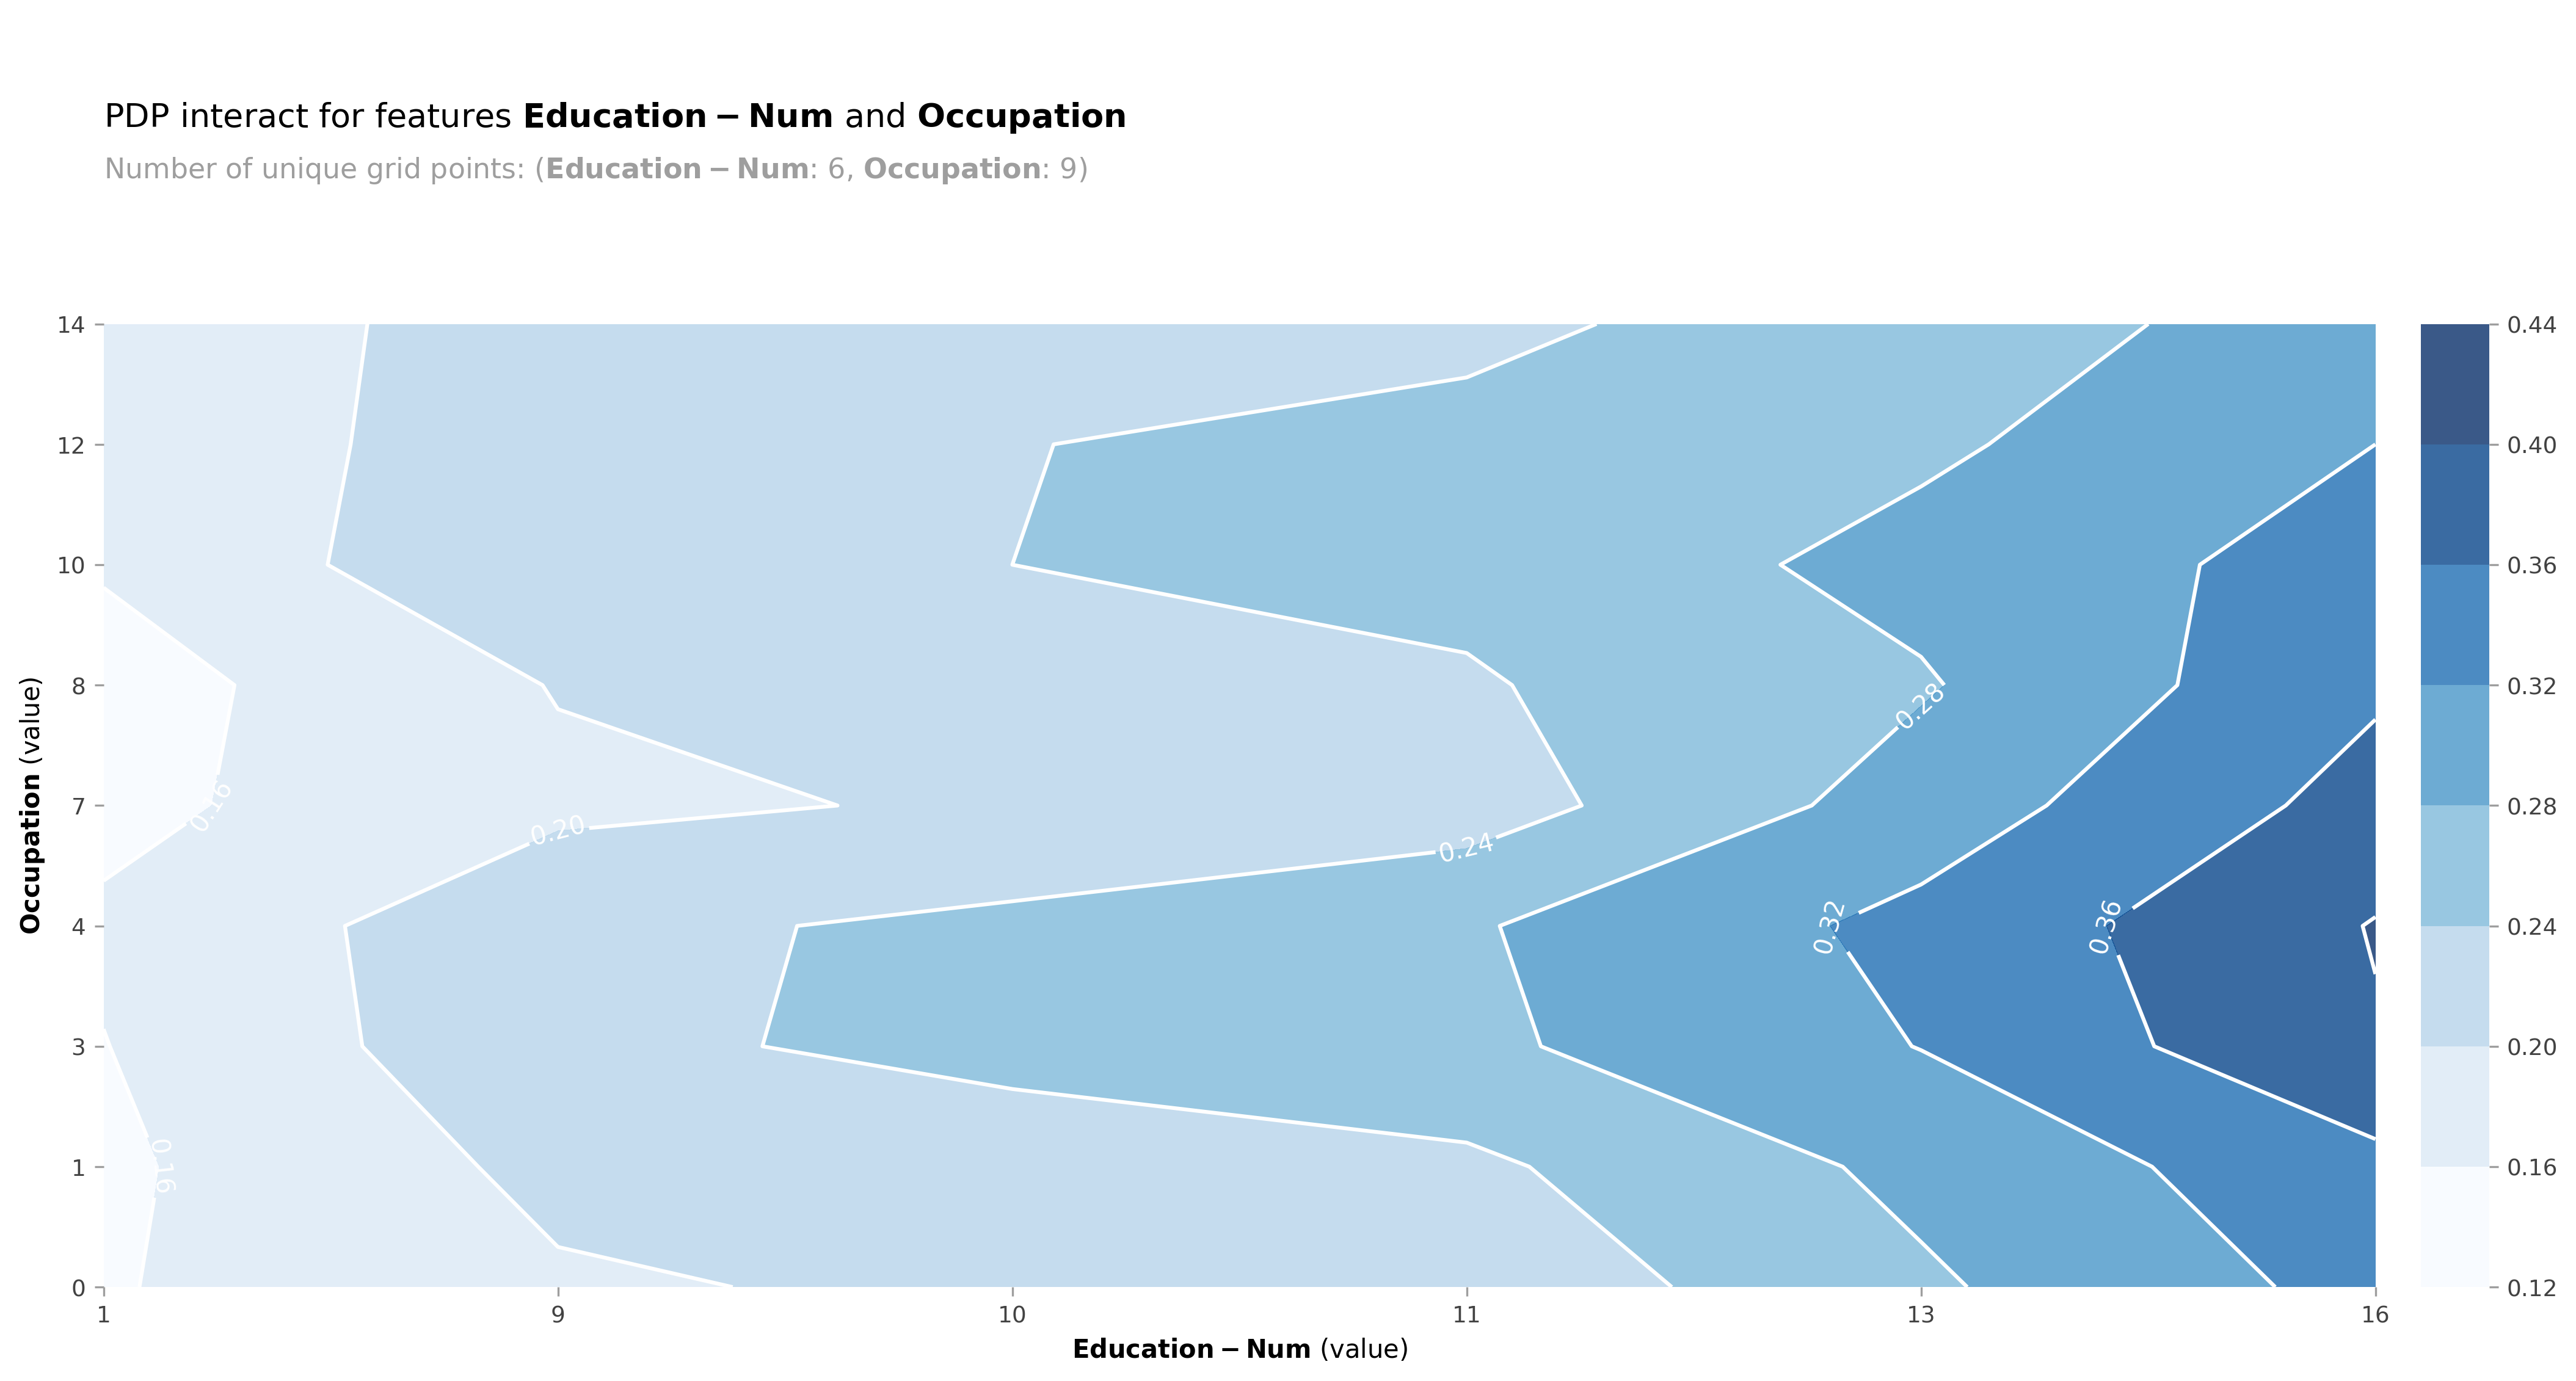

In [35]:
from pdpbox import pdp
import pdpbox
import matplotlib.pyplot as plt

# Create the data that we will plot
# pdp.PDPIsolate
pdp = pdp.PDPInteract(model=knn, df=X_valid.copy(), model_features=X.columns, feature_names=['Education-Num', 'Occupation'], features=['Education-Num', 'Occupation'], n_classes = 2)

# plot it
fig, axes = pdp.plot(engine='matplotlib')
plt.show()


In [36]:
explainer_lime = lime.lime_tabular.LimeTabularExplainer(X_train.values, feature_names=X.columns,
                                                   class_names=['Larger 50k', "Less 50k"], discretize_continuous=True)

exp = explainer_lime.explain_instance(X_valid.iloc[38], knn.predict_proba, num_features=12, top_labels=2)
exp.show_in_notebook(show_table=True, show_all=True)

In [37]:
import warnings
warnings.filterwarnings('ignore')

In [38]:
def f(x):
    return knn.predict_proba(x)[:, 1]


med = X_train.median().values.reshape((1, X_train.shape[1]))

explainer = shap.Explainer(f, med)
shap_values = explainer(X_train.iloc[0:1000, :])

PermutationExplainer explainer: 801it [00:46, 13.47it/s]                         


In [39]:
med

array([[36.,  4., 10.,  2.,  7.,  3.,  4.,  1.,  0.,  0., 40., 39.]])

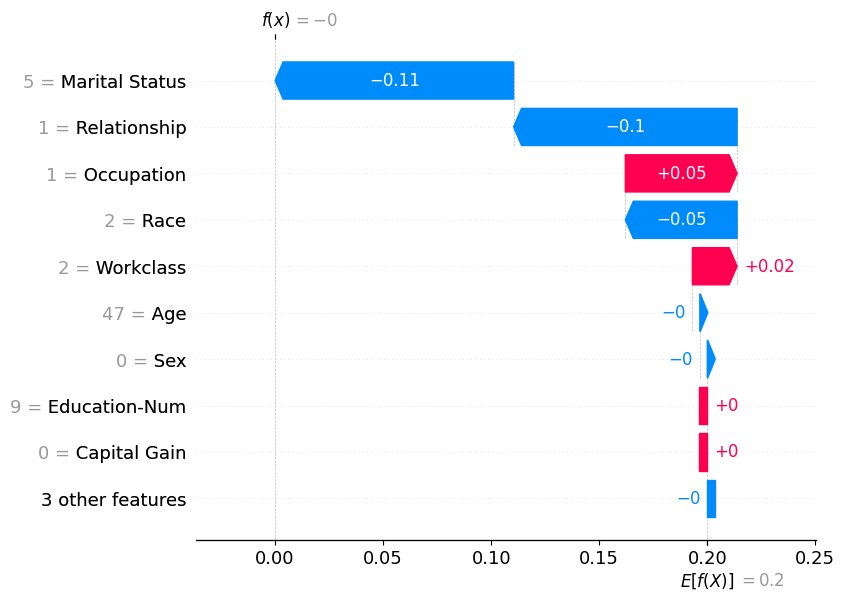

In [40]:
shap.plots.waterfall(shap_values[130])

A summary beeswarm plot is an even better way to see the relative impact of all features over the entire dataset. Features are sorted by the sum of their SHAP value magnitudes across all samples.

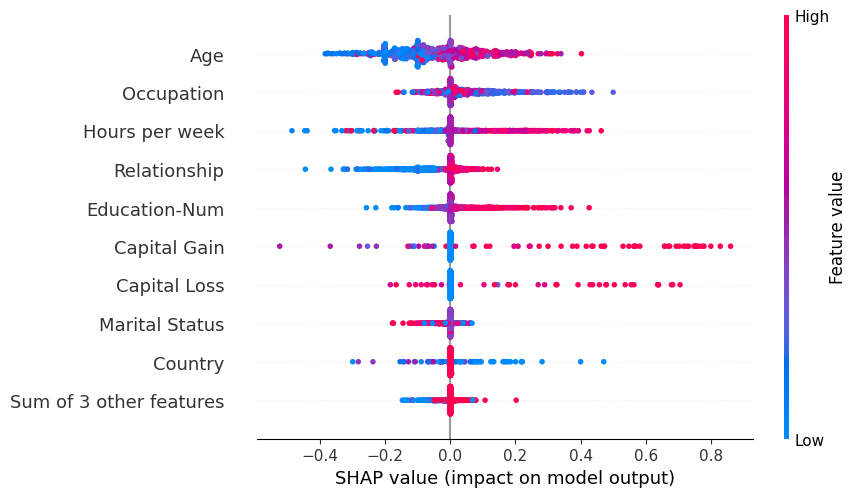

In [41]:
shap.plots.beeswarm(shap_values)

A heatmap plot provides another global view of the model's behavior, this time with a focus on population subgroups.

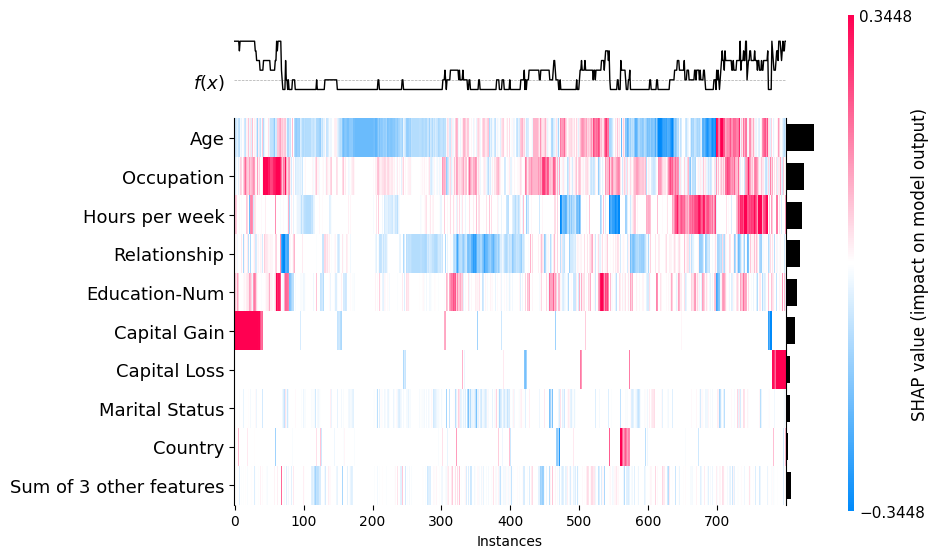

<Axes: xlabel='Instances'>

In [42]:
shap.plots.heatmap(shap_values)

With a summary plot with see marital status is the most important on average, but other features (such as captial gain) can have more impact on a particular individual.

A dependence scatter plot shows how the number of years of education increases the chance of making over 50K annually.

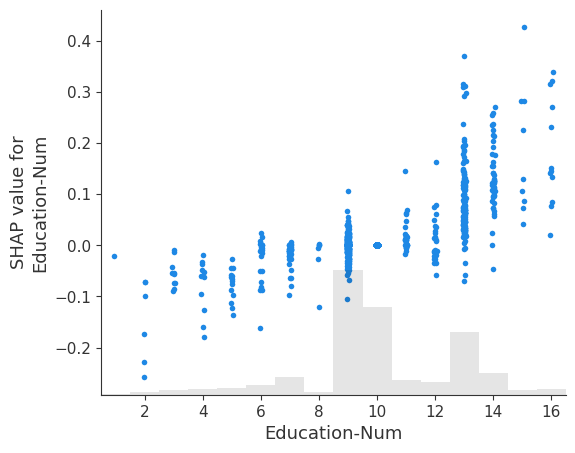

In [44]:
shap.plots.scatter(shap_values[:, "Education-Num"])

<hr>
Have an idea for more helpful examples? Pull requests that add to this documentation notebook are encouraged!